# BFC Competitor Check 2026
## Notebook 06: Feature Engineering

### Purpose

Prepare clearly defined features for descriptive comparisons
and management reporting.

### Research Alignment

Features must support RQ01 through RQ10 and preserve the
limitations identified during cleaning and exploration.

### Rules

Preserve the original prepared datasets.

Retain observation identifiers and source references.

Distinguish missing information from a confirmed absence.

Do not convert cup labels into measured beverage volumes.

Keep advertised package costs separate from total investment.

Retain provisional customer coding and unresolved evidence.

Derived features do not automatically establish suitability
for predictive modeling.

### First Step

Load the candidate price comparisons and size price schedules
exported by Notebook 04.

These tables describe selected published menus.
They do not establish confirmed savings or customer value.

In [2]:
from pathlib import Path

import pandas as pd
from IPython.display import display

# Locate the saved EDA tables.

project_root = Path.cwd().resolve()

while (
    not (project_root / "reports" / "eda" / "price_pairs.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

eda_path = project_root / "reports" / "eda"

if not (eda_path / "price_pairs.csv").is_file():
    raise FileNotFoundError(
        "Run Notebook 04 and export its analysis tables first."
    )

# Load the two descriptive comparison tables.

price_pairs = pd.read_csv(
    eda_path / "price_pairs.csv",
    dtype="string",
)

size_price_pairs = pd.read_csv(
    eda_path / "size_price_pairs.csv",
    dtype="string",
)

# Restore numeric price columns.
# Invalid numeric text will stop execution.

price_columns = [
    "displayed_price_php_bfc",
    "displayed_price_php_cbtl",
    "cbtl_minus_bfc_php",
]

for column in price_columns:
    price_pairs[column] = pd.to_numeric(
        price_pairs[column],
        errors="raise",
    ).astype("Float64")

size_price_columns = [
    "displayed_price_php_12oz",
    "displayed_price_php_16oz",
    "price_increment_php",
]

for column in size_price_columns:
    size_price_pairs[column] = pd.to_numeric(
        size_price_pairs[column],
        errors="raise",
    ).astype("Float64")

print("Candidate published price comparisons:")
display(price_pairs.head())

print("\nPublished size price schedules:")
display(size_price_pairs.head())

print("Candidate price pairs:", len(price_pairs))
print("Size price schedules:", len(size_price_pairs))
print("No new features created yet. No files changed.")

Candidate published price comparisons:


,comparison_group,temperature,size_label_standardised,channel,observation_id_bfc,source_id_bfc,displayed_price_php_bfc,observation_id_cbtl,source_id_cbtl,displayed_price_php_cbtl,cbtl_minus_bfc_php
0,Americano,Hot,12oz,Official website,MNU0004,SRC0030,110.0,MNU0112,SRC0121,140.0,30.0
1,Americano,Hot,16oz,Official website,MNU0005,SRC0030,120.0,MNU0113,SRC0121,155.0,35.0
2,Cafe latte,Hot,12oz,Official website,MNU0016,SRC0031,130.0,MNU0118,SRC0121,135.0,5.0
3,Cafe latte,Hot,16oz,Official website,MNU0017,SRC0031,140.0,MNU0119,SRC0121,150.0,10.0
4,Spanish latte,Hot,12oz,Official website,MNU0023,SRC0032,130.0,MNU0124,SRC0121,175.0,45.0



Published size price schedules:


,observation_id_12oz,brand_id,source_id_12oz,comparison_group,temperature,channel,location_scope,displayed_price_php_12oz,observation_id_16oz,source_id_16oz,displayed_price_php_16oz,brand_name,price_increment_php
0,MNU0004,BFC001,SRC0030,Americano,Hot,Official website,Not stated in captured text,110.0,MNU0005,SRC0030,120.0,"But First, Coffee",10.0
1,MNU0112,BFC023,SRC0121,Americano,Hot,Official website,Official Philippine menu; branch applicability...,140.0,MNU0113,SRC0121,155.0,The Coffee Bean & Tea Leaf,15.0
2,MNU0008,BFC001,SRC0030,Americano,Iced,Official website,Not stated in captured text,110.0,MNU0009,SRC0030,120.0,"But First, Coffee",10.0
3,MNU0115,BFC023,SRC0121,Americano,Iced,Official website,Official Philippine menu; branch applicability...,140.0,MNU0116,SRC0121,155.0,The Coffee Bean & Tea Leaf,15.0
4,MNU0016,BFC001,SRC0031,Cafe latte,Hot,Official website,Not stated in captured text,130.0,MNU0017,SRC0031,140.0,"But First, Coffee",10.0


Candidate price pairs: 12
Size price schedules: 12
No new features created yet. No files changed.


## 1. Published Price Features

### Research Question

RQ01: How does BFC pricing compare with equivalent competitor products?

### Definitions

CBTL price gap percentage uses the recorded CBTL price as its
denominator. It expresses the recorded price difference relative
to that benchmark.

Size upgrade percentage uses the recorded 12oz price as its
denominator. It expresses the additional price for the 16oz label.

### Limitations

These features describe candidate published menu comparisons.

They do not establish promotional savings, actual beverage
volume, ingredient equivalence or confirmed checkout prices.

Hot and iced schedules remain separate records, but repeated
price patterns are not independent evidence.

In [3]:
# Create feature tables while preserving the loaded comparisons.

pricing_features = price_pairs.copy()
size_features = size_price_pairs.copy()

# Require complete, positive prices for percentage denominators.

pair_prices = pricing_features[
    ["displayed_price_php_bfc", "displayed_price_php_cbtl"]
]

size_prices = size_features[
    ["displayed_price_php_12oz", "displayed_price_php_16oz"]
]

if pair_prices.isna().any().any() or size_prices.isna().any().any():
    raise ValueError("Missing prices found. Review before calculation.")

if pair_prices.le(0).any().any() or size_prices.le(0).any().any():
    raise ValueError("Nonpositive prices found. Review before calculation.")

# Recalculate differences from their underlying prices.

pricing_features["cbtl_minus_bfc_php"] = (
    pricing_features["displayed_price_php_cbtl"]
    - pricing_features["displayed_price_php_bfc"]
)

pricing_features["gap_pct_of_cbtl_price"] = (
    pricing_features["cbtl_minus_bfc_php"]
    / pricing_features["displayed_price_php_cbtl"]
    * 100
)

size_features["price_increment_php"] = (
    size_features["displayed_price_php_16oz"]
    - size_features["displayed_price_php_12oz"]
)

size_features["upgrade_pct_of_12oz_price"] = (
    size_features["price_increment_php"]
    / size_features["displayed_price_php_12oz"]
    * 100
)

# Carry evidence qualifications into the derived tables.

pricing_features["comparison_status"] = (
    "Candidate; equivalence, freshness and branch applicability unresolved"
)

size_features["comparison_status"] = (
    "Published schedule; freshness and branch applicability unresolved"
)

print("Candidate published price features:")
display(
    pricing_features[
        [
            "comparison_group",
            "temperature",
            "size_label_standardised",
            "displayed_price_php_bfc",
            "displayed_price_php_cbtl",
            "cbtl_minus_bfc_php",
            "gap_pct_of_cbtl_price",
        ]
    ].round(2)
)

print("\nPublished size upgrade features:")
display(
    size_features[
        [
            "brand_name",
            "comparison_group",
            "temperature",
            "displayed_price_php_12oz",
            "displayed_price_php_16oz",
            "price_increment_php",
            "upgrade_pct_of_12oz_price",
        ]
    ].round(2)
)

print("Source and observation identifiers retained.")
print("Percentages describe recorded prices, not confirmed savings.")
print("No files changed.")

Candidate published price features:


,comparison_group,temperature,size_label_standardised,displayed_price_php_bfc,displayed_price_php_cbtl,cbtl_minus_bfc_php,gap_pct_of_cbtl_price
0,Americano,Hot,12oz,110.0,140.0,30.0,21.43
1,Americano,Hot,16oz,120.0,155.0,35.0,22.58
2,Cafe latte,Hot,12oz,130.0,135.0,5.0,3.7
3,Cafe latte,Hot,16oz,140.0,150.0,10.0,6.67
4,Spanish latte,Hot,12oz,130.0,175.0,45.0,25.71
5,Spanish latte,Hot,16oz,140.0,185.0,45.0,24.32
6,Americano,Iced,12oz,110.0,140.0,30.0,21.43
7,Americano,Iced,16oz,120.0,155.0,35.0,22.58
8,Cafe latte,Iced,12oz,130.0,135.0,5.0,3.7
9,Cafe latte,Iced,16oz,140.0,150.0,10.0,6.67



Published size upgrade features:


,brand_name,comparison_group,temperature,displayed_price_php_12oz,displayed_price_php_16oz,price_increment_php,upgrade_pct_of_12oz_price
0,"But First, Coffee",Americano,Hot,110.0,120.0,10.0,9.09
1,The Coffee Bean & Tea Leaf,Americano,Hot,140.0,155.0,15.0,10.71
2,"But First, Coffee",Americano,Iced,110.0,120.0,10.0,9.09
3,The Coffee Bean & Tea Leaf,Americano,Iced,140.0,155.0,15.0,10.71
4,"But First, Coffee",Cafe latte,Hot,130.0,140.0,10.0,7.69
5,The Coffee Bean & Tea Leaf,Cafe latte,Hot,135.0,150.0,15.0,11.11
6,"But First, Coffee",Cafe latte,Iced,130.0,140.0,10.0,7.69
7,The Coffee Bean & Tea Leaf,Cafe latte,Iced,135.0,150.0,15.0,11.11
8,"But First, Coffee",Spanish latte,Hot,130.0,140.0,10.0,7.69
9,The Coffee Bean & Tea Leaf,Spanish latte,Hot,175.0,185.0,10.0,5.71


Source and observation identifiers retained.
Percentages describe recorded prices, not confirmed savings.
No files changed.


### Published Price Feature Findings

The candidate BFC prices are between 3.70 percent and
25.71 percent below the corresponding recorded CBTL prices,
using CBTL as the denominator.

Spanish latte has the largest percentage gap.
Cafe latte has the smallest.

BFC applies a PHP 10 size increment across the three selected
products. Its percentage increment varies because the starting
prices differ.

For Spanish latte, both brands apply a PHP 10 increment.
This represents 7.69 percent of BFC's 12oz price and
5.71 percent of CBTL's 12oz price.

### Business Interpretation

Absolute and percentage differences answer different questions.

The PHP increment describes the additional published charge.
The percentage describes that charge relative to the specified
starting price.

A smaller percentage increment does not necessarily mean a
smaller additional charge.

### Qualifications

These features describe selected published menus.
Product equivalence, freshness and branch applicability remain
unresolved.

The percentages do not establish promotional savings,
measured beverage value, customer demand or profitability.

Hot and iced records repeat the same price patterns.
Do not treat them as independent confirmations.

In [4]:
# Define the derived features and their permitted interpretation.

feature_dictionary = pd.DataFrame(
    [
        {
            "table": "pricing_features",
            "feature": "cbtl_minus_bfc_php",
            "research_question_id": "RQ01",
            "definition": "Recorded CBTL price minus recorded BFC price",
            "formula": "displayed_price_php_cbtl - displayed_price_php_bfc",
            "unit": "PHP",
            "denominator": "Not applicable",
            "interpretation": "Positive means the recorded CBTL price is higher",
            "qualification": (
                "Candidate comparison. Equivalence, freshness and "
                "branch applicability remain unresolved."
            ),
        },
        {
            "table": "pricing_features",
            "feature": "gap_pct_of_cbtl_price",
            "research_question_id": "RQ01",
            "definition": "Recorded price gap as a percentage of CBTL price",
            "formula": (
                "cbtl_minus_bfc_php / displayed_price_php_cbtl * 100"
            ),
            "unit": "Percent",
            "denominator": "Positive recorded CBTL price",
            "interpretation": "Relative published price gap using CBTL as benchmark",
            "qualification": (
                "Not a verified discount, promotional saving or value measure."
            ),
        },
        {
            "table": "size_features",
            "feature": "price_increment_php",
            "research_question_id": "RQ01",
            "definition": "Recorded 16oz price minus recorded 12oz price",
            "formula": (
                "displayed_price_php_16oz - displayed_price_php_12oz"
            ),
            "unit": "PHP",
            "denominator": "Not applicable",
            "interpretation": "Additional published charge for the larger cup label",
            "qualification": (
                "Cup labels do not establish measured beverage volumes."
            ),
        },
        {
            "table": "size_features",
            "feature": "upgrade_pct_of_12oz_price",
            "research_question_id": "RQ01",
            "definition": "Size price increment as a percentage of the 12oz price",
            "formula": (
                "price_increment_php / displayed_price_php_12oz * 100"
            ),
            "unit": "Percent",
            "denominator": "Positive recorded 12oz price",
            "interpretation": "Relative additional charge using 12oz as the base",
            "qualification": (
                "Not a measure of additional beverage volume or customer value."
            ),
        },
    ]
)

with pd.option_context("display.max_colwidth", None):
    display(feature_dictionary)

print("Derived numeric features documented:", len(feature_dictionary))
print("Observation and source identifiers remain in the feature tables.")
print("comparison_status retains the evidence qualification for each row.")
print("No files changed.")

,table,feature,research_question_id,definition,formula,unit,denominator,interpretation,qualification
0,pricing_features,cbtl_minus_bfc_php,RQ01,Recorded CBTL price minus recorded BFC price,displayed_price_php_cbtl - displayed_price_php_bfc,PHP,Not applicable,Positive means the recorded CBTL price is higher,"Candidate comparison. Equivalence, freshness and branch applicability remain unresolved."
1,pricing_features,gap_pct_of_cbtl_price,RQ01,Recorded price gap as a percentage of CBTL price,cbtl_minus_bfc_php / displayed_price_php_cbtl * 100,Percent,Positive recorded CBTL price,Relative published price gap using CBTL as benchmark,"Not a verified discount, promotional saving or value measure."
2,size_features,price_increment_php,RQ01,Recorded 16oz price minus recorded 12oz price,displayed_price_php_16oz - displayed_price_php_12oz,PHP,Not applicable,Additional published charge for the larger cup label,Cup labels do not establish measured beverage volumes.
3,size_features,upgrade_pct_of_12oz_price,RQ01,Size price increment as a percentage of the 12oz price,price_increment_php / displayed_price_php_12oz * 100,Percent,Positive recorded 12oz price,Relative additional charge using 12oz as the base,Not a measure of additional beverage volume or customer value.


Derived numeric features documented: 4
Observation and source identifiers remain in the feature tables.
comparison_status retains the evidence qualification for each row.
No files changed.


In [5]:
from datetime import datetime
import shutil

# Validate the feature tables before saving.

if len(pricing_features) != len(price_pairs):
    raise ValueError("Candidate price comparison count changed.")

if len(size_features) != len(size_price_pairs):
    raise ValueError("Size schedule count changed.")

for table_name, table in [
    ("pricing_features", pricing_features),
    ("size_features", size_features),
]:
    if table["comparison_status"].isna().any():
        raise ValueError(f"Missing evidence qualification: {table_name}")

for _, definition in feature_dictionary.iterrows():
    table_name = definition["table"]
    feature = definition["feature"]

    if table_name == "pricing_features":
        table = pricing_features
    else:
        table = size_features

    if feature not in table.columns:
        raise ValueError(f"Documented feature not found: {feature}")

    if table[feature].isna().any():
        raise ValueError(f"Missing calculated values: {feature}")

# Keep feature outputs separate from the prepared source tables.

features_path = project_root / "data" / "processed" / "features"
features_path.mkdir(parents=True, exist_ok=True)

feature_tables = {
    "pricing_features": pricing_features,
    "size_features": size_features,
    "feature_dictionary": feature_dictionary,
}

# Back up existing outputs before replacing them.

existing_files = [
    features_path / f"{name}.csv"
    for name in feature_tables
    if (features_path / f"{name}.csv").is_file()
]

if existing_files:
    backup_label = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    backup_path = features_path / "backups" / backup_label
    backup_path.mkdir(parents=True, exist_ok=True)

    for file_path in existing_files:
        shutil.copy2(file_path, backup_path / file_path.name)

# Save without rounding the underlying numeric values.

saved_features = []

for name, table in feature_tables.items():
    table.to_csv(features_path / f"{name}.csv", index=False)

    saved_features.append(
        {
            "file": f"{name}.csv",
            "records_saved": len(table),
            "columns_saved": len(table.columns),
        }
    )

display(pd.DataFrame(saved_features))

print("Saved folder:", features_path)
print("Raw datasets and prepared source tables were not changed.")
print("Features retain their descriptive evidence qualifications.")

,file,records_saved,columns_saved
0,pricing_features.csv,12,13
1,size_features.csv,12,15
2,feature_dictionary.csv,4,9


Saved folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/data/processed/features
Raw datasets and prepared source tables were not changed.
Features retain their descriptive evidence qualifications.


## Feature Engineering Conclusion

Two descriptive feature tables and a dictionary were saved
under data/processed/features.

pricing_features contains 12 candidate price comparisons.
size_features contains 12 published size price schedules.
feature_dictionary documents four derived numeric features.

Observation identifiers, source references and evidence
qualifications remain attached to the feature tables.

These features support RQ01 reporting. They do not resolve
product equivalence, price freshness or branch applicability.

Other research questions retain their existing descriptive
outputs and collection requirements.

Raw datasets and prepared source tables remain unchanged.

### Modeling Readiness

No prediction target or suitable validation dataset has been
established.

The derived price features are arithmetic descriptions of
published menus. Predicting a price difference from the same
prices used to calculate it would reproduce a formula rather
than provide a useful forecast.

Notebook 07 will document modeling readiness before any model
is selected or trained.

In [6]:
features_path = project_root / "data/processed/features"

pricing_features = pd.read_csv(
    features_path / "pricing_features.csv"
)

size_features = pd.read_csv(
    features_path / "size_features.csv"
)

feature_dictionary = pd.read_csv(
    features_path / "feature_dictionary.csv",
    dtype="string"
)

print("Pricing feature rows:", len(pricing_features))
print(pricing_features.columns.tolist())

print("\nSize feature rows:", len(size_features))
print(size_features.columns.tolist())

display(feature_dictionary)

Pricing feature rows: 12
['comparison_group', 'temperature', 'size_label_standardised', 'channel', 'observation_id_bfc', 'source_id_bfc', 'displayed_price_php_bfc', 'observation_id_cbtl', 'source_id_cbtl', 'displayed_price_php_cbtl', 'cbtl_minus_bfc_php', 'gap_pct_of_cbtl_price', 'comparison_status']

Size feature rows: 12
['observation_id_12oz', 'brand_id', 'source_id_12oz', 'comparison_group', 'temperature', 'channel', 'location_scope', 'displayed_price_php_12oz', 'observation_id_16oz', 'source_id_16oz', 'displayed_price_php_16oz', 'brand_name', 'price_increment_php', 'upgrade_pct_of_12oz_price', 'comparison_status']


,table,feature,research_question_id,definition,formula,unit,denominator,interpretation,qualification
0,pricing_features,cbtl_minus_bfc_php,RQ01,Recorded CBTL price minus recorded BFC price,displayed_price_php_cbtl - displayed_price_php...,PHP,Not applicable,Positive means the recorded CBTL price is higher,"Candidate comparison. Equivalence, freshness a..."
1,pricing_features,gap_pct_of_cbtl_price,RQ01,Recorded price gap as a percentage of CBTL price,cbtl_minus_bfc_php / displayed_price_php_cbtl ...,Percent,Positive recorded CBTL price,Relative published price gap using CBTL as ben...,"Not a verified discount, promotional saving or..."
2,size_features,price_increment_php,RQ01,Recorded 16oz price minus recorded 12oz price,displayed_price_php_16oz - displayed_price_php...,PHP,Not applicable,Additional published charge for the larger cup...,Cup labels do not establish measured beverage ...
3,size_features,upgrade_pct_of_12oz_price,RQ01,Size price increment as a percentage of the 12...,price_increment_php / displayed_price_php_12oz...,Percent,Positive recorded 12oz price,Relative additional charge using 12oz as the base,Not a measure of additional beverage volume or...


In [7]:
menu_lookup = pd.read_csv(
    features_path.parent / "menu_pricing.csv",
    dtype="string"
)

valid_observations = menu_lookup["observation_id"]
valid_sources = menu_lookup["source_id"]

feature_link_check = pd.DataFrame({
    "reference": [
        "Pricing BFC observation",
        "Pricing CBTL observation",
        "Pricing BFC source",
        "Pricing CBTL source",
        "Size 12oz observation",
        "Size 16oz observation",
        "Size 12oz source",
        "Size 16oz source"
    ],
    "all_links_found": [
        pricing_features["observation_id_bfc"].isin(valid_observations).all(),
        pricing_features["observation_id_cbtl"].isin(valid_observations).all(),
        pricing_features["source_id_bfc"].isin(valid_sources).all(),
        pricing_features["source_id_cbtl"].isin(valid_sources).all(),
        size_features["observation_id_12oz"].isin(valid_observations).all(),
        size_features["observation_id_16oz"].isin(valid_observations).all(),
        size_features["source_id_12oz"].isin(valid_sources).all(),
        size_features["source_id_16oz"].isin(valid_sources).all()
    ]
})

display(feature_link_check)

,reference,all_links_found
0,Pricing BFC observation,True
1,Pricing CBTL observation,True
2,Pricing BFC source,True
3,Pricing CBTL source,True
4,Size 12oz observation,True
5,Size 16oz observation,True
6,Size 12oz source,True
7,Size 16oz source,True


In [8]:
menu_lookup["displayed_price_php"] = pd.to_numeric(
    menu_lookup["displayed_price_php"],
    errors="raise"
)

menu_by_id = menu_lookup.set_index("observation_id")

if not menu_by_id.index.is_unique:
    raise ValueError("Duplicate observation IDs found in the prepared menu.")

feature_value_checks = []

for label, table, observation_field, source_field, price_field in [
    (
        "Pricing BFC", pricing_features,
        "observation_id_bfc", "source_id_bfc",
        "displayed_price_php_bfc"
    ),
    (
        "Pricing CBTL", pricing_features,
        "observation_id_cbtl", "source_id_cbtl",
        "displayed_price_php_cbtl"
    ),
    (
        "Size 12oz", size_features,
        "observation_id_12oz", "source_id_12oz",
        "displayed_price_php_12oz"
    ),
    (
        "Size 16oz", size_features,
        "observation_id_16oz", "source_id_16oz",
        "displayed_price_php_16oz"
    )
]:
    expected_source = table[observation_field].map(
        menu_by_id["source_id"]
    )

    expected_price = table[observation_field].map(
        menu_by_id["displayed_price_php"]
    )

    source_matches = table[source_field].eq(
        expected_source
    ).fillna(False)

    price_matches = (
        table[price_field].sub(expected_price).abs().le(0.005)
    ).fillna(False)

    feature_value_checks.append({
        "comparison": label,
        "records_checked": len(table),
        "source_mismatches": int((~source_matches).sum()),
        "price_mismatches": int((~price_matches).sum())
    })

display(pd.DataFrame(feature_value_checks))

,comparison,records_checked,source_mismatches,price_mismatches
0,Pricing BFC,12,0,0
1,Pricing CBTL,12,0,0
2,Size 12oz,12,0,0
3,Size 16oz,12,0,0


In [9]:
feature_formula_check = pd.DataFrame({
    "feature": [
        "cbtl_minus_bfc_php",
        "gap_pct_of_cbtl_price",
        "price_increment_php",
        "upgrade_pct_of_12oz_price"
    ],
    "all_values_match": [
        pricing_features["cbtl_minus_bfc_php"].round(2).eq(
            (
                pricing_features["displayed_price_php_cbtl"]
                - pricing_features["displayed_price_php_bfc"]
            ).round(2)
        ).all(),

        pricing_features["gap_pct_of_cbtl_price"].round(2).eq(
            (
                pricing_features["cbtl_minus_bfc_php"]
                / pricing_features["displayed_price_php_cbtl"]
                * 100
            ).round(2)
        ).all(),

        size_features["price_increment_php"].round(2).eq(
            (
                size_features["displayed_price_php_16oz"]
                - size_features["displayed_price_php_12oz"]
            ).round(2)
        ).all(),

        size_features["upgrade_pct_of_12oz_price"].round(2).eq(
            (
                size_features["price_increment_php"]
                / size_features["displayed_price_php_12oz"]
                * 100
            ).round(2)
        ).all()
    ]
})

display(feature_formula_check)

,feature,all_values_match
0,cbtl_minus_bfc_php,True
1,gap_pct_of_cbtl_price,True
2,price_increment_php,True
3,upgrade_pct_of_12oz_price,True


### Feature validation findings

The pricing and size feature tables each contain 12 records.

All linked observation and source identifiers exist in the prepared
menu. Saved prices and source assignments match their linked
observations. All four derived formulas match the documented
calculations to two decimal places.

These checks establish calculation and reference consistency.
Product equivalence, freshness and branch applicability remain
subject to the recorded comparison qualifications.

Supplementary local starting prices are not added to these
comparison features because serving equivalence remains unresolved.

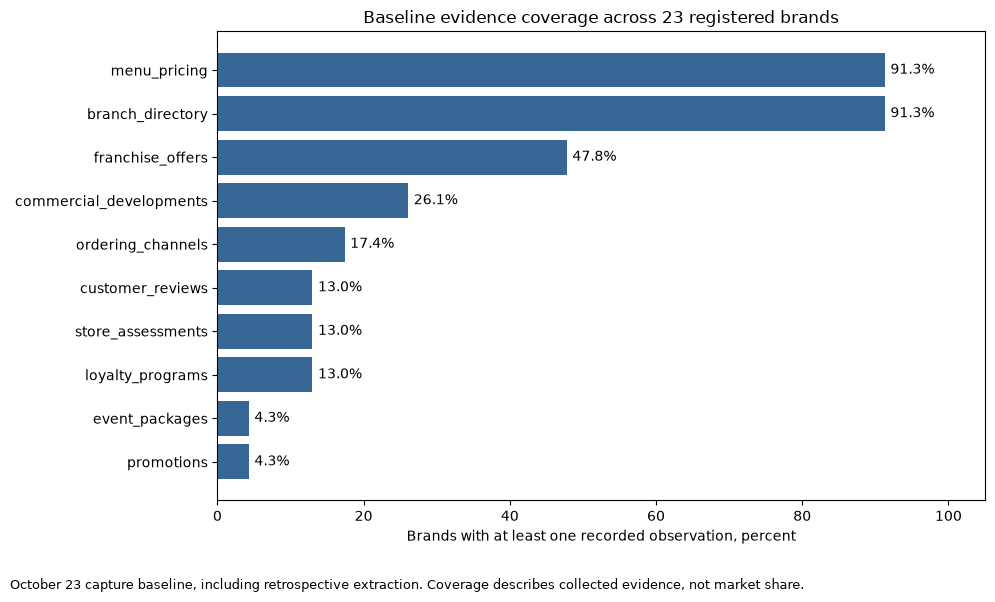

In [13]:
import matplotlib.pyplot as plt

coverage_plot = coverage_summary.sort_values("coverage_percent")

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    coverage_plot["dataset"],
    coverage_plot["coverage_percent"],
    color="#376795"
)

ax.set(
    title="Baseline evidence coverage across 23 registered brands",
    xlabel="Brands with at least one recorded observation, percent",
    ylabel="",
    xlim=(0, 105)
)

ax.bar_label(
    ax.containers[0],
    labels=[
        f"{value:.1f}%"
        for value in coverage_plot["coverage_percent"]
    ],
    padding=4
)

fig.text(
    0.01,
    0.01,
    "October 23 capture baseline, including retrospective extraction. "
    "Coverage describes collected evidence, not market share.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

### Evidence coverage interpretation

Menu pricing and branch records cover 21 of the 23 registered brands.
This indicates broad brand inclusion, but does not establish complete
menus, verified branch networks or comparable observations.

Promotion and event package records each cover one brand. Loyalty,
store assessments and customer comments each cover three brands.
These gaps limit comparisons across competitors.

Collection should prioritize comparable evidence for the selected
competitors and locations. Adding more records alone will not resolve
differences in serving size, channel, branch scope or offer conditions.

In [14]:
figures_path = project_root / "reports/figures"
figures_path.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_path / "baseline_evidence_coverage.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved:", figures_path / "baseline_evidence_coverage.png")

Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/reports/figures/baseline_evidence_coverage.png


In [15]:
local_price_verification = pd.read_csv(
    project_root / "data/interim/local_price_verification.csv",
    dtype="string"
)

price_columns = [
    "displayed_price_php",
    "displayed_reference_price_php"
]

for column in price_columns:
    local_price_verification[column] = pd.to_numeric(
        local_price_verification[column],
        errors="raise"
    )

bfc_americano_plot = local_price_verification.loc[
    local_price_verification["comparison_role"].eq("BFC study branch")
    & local_price_verification["product_check"].eq("Americano"),
    [
        "business_name",
        "displayed_price_php",
        "displayed_reference_price_php"
    ]
].copy()

display(bfc_americano_plot)

,business_name,displayed_price_php,displayed_reference_price_php
0,Diliman,116.0,145.0
5,Molino III,145.0,<NA>
10,Jones,123.25,145.0
15,T. Chavez,145.0,<NA>


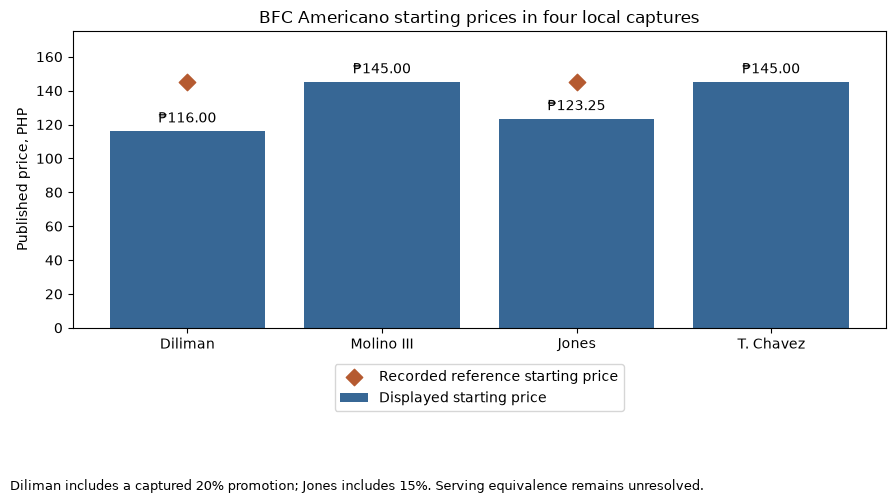

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    bfc_americano_plot["business_name"],
    bfc_americano_plot["displayed_price_php"].astype(float),
    color="#376795",
    label="Displayed starting price"
)

reference_prices = bfc_americano_plot.dropna(
    subset=["displayed_reference_price_php"]
)

ax.scatter(
    reference_prices["business_name"],
    reference_prices["displayed_reference_price_php"].astype(float),
    color="#B55A30",
    marker="D",
    s=70,
    label="Recorded reference starting price",
    zorder=3
)

ax.bar_label(
    ax.containers[0],
    labels=[
        f"₱{price:,.2f}"
        for price in bfc_americano_plot["displayed_price_php"]
    ],
    padding=4
)

ax.set(
    title="BFC Americano starting prices in four local captures",
    ylabel="Published price, PHP",
    ylim=(0, 175)
)

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.10))

fig.text(
    0.01,
    0.01,
    "Diliman includes a captured 20% promotion; Jones includes 15%. "
    "Serving equivalence remains unresolved.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

In [17]:
fig.savefig(
    figures_path / "local_bfc_americano_starting_prices.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved:", figures_path / "local_bfc_americano_starting_prices.png")

Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/reports/figures/local_bfc_americano_starting_prices.png


### Interpretation

Diliman and Jones show lower displayed starting prices alongside
captured promotions of 20% and 15%, respectively.

Both branches show a reference starting price of PHP 145, matching
the displayed starting prices at Molino III and T. Chavez.

The observed differences therefore reflect promotion exposure in
these captures. They do not establish regional pricing policies,
equivalent servings or customer transaction prices.

No promotion performance or profitability conclusion is supported
without sales, cost and promotion funding data.

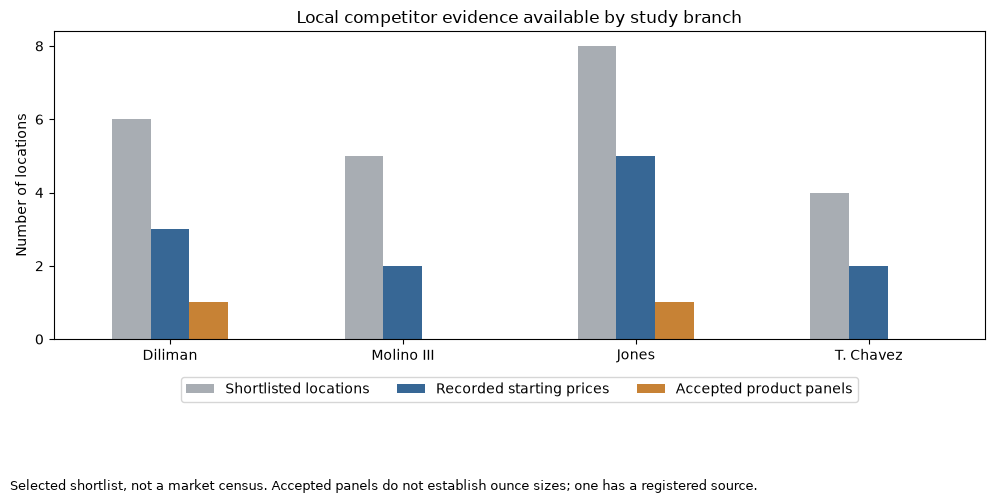

In [18]:
local_site_evidence_summary = pd.read_csv(
    project_root
    / "reports/supplementary/local_site_evidence_summary.csv"
)

local_coverage_plot = local_site_evidence_summary.set_index(
    "branch_name"
)[
    [
        "shortlisted_competitors",
        "recorded_starting_prices",
        "accepted_size_panels"
    ]
]

fig, ax = plt.subplots(figsize=(10, 5))

local_coverage_plot.plot.bar(
    ax=ax,
    color=["#A8ADB3", "#376795", "#C78235"],
    rot=0
)

ax.set(
    title="Local competitor evidence available by study branch",
    xlabel="",
    ylabel="Number of locations"
)

ax.set_yticks(range(0, 10, 2))

ax.legend(
    [
        "Shortlisted locations",
        "Recorded starting prices",
        "Accepted product panels"
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=3
)

fig.text(
    0.01,
    0.01,
    "Selected shortlist, not a market census. "
    "Accepted panels do not establish ounce sizes; one has a registered source.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.14, 1, 1])
plt.show()

In [19]:
fig.savefig(
    figures_path / "local_competitor_evidence_coverage.png",
    dpi=300,
    bbox_inches="tight"
)

### Local evidence coverage

The selected shortlist contains 23 competitor locations.
Starting prices were recorded for 12 locations, while two product
panels retained the intended branch during inspection.

Diliman and Jones each have one accepted panel. Molino III and
T. Chavez have none. Ounce sizes remain unresolved in both accepted
panels, and only one currently links to a registered source.

These counts describe collection progress. They do not measure
competitive intensity or support ranking the four local markets.

In [20]:
notebook_files = sorted(project_root.rglob("*.ipynb"))

for notebook_file in notebook_files:
    if ".ipynb_checkpoints" not in notebook_file.parts:
        print(notebook_file.relative_to(project_root))

.virtual_documents/notebooks/01_business_understanding.ipynb
.virtual_documents/notebooks/02_data_collection.ipynb
.virtual_documents/notebooks/03_data_cleaning.ipynb
.virtual_documents/notebooks/04_exploratory_data_analysis.ipynb
.virtual_documents/notebooks/05_hypothesis_testing.ipynb
.virtual_documents/notebooks/06_feature_engineering.ipynb
.virtual_documents/notebooks/07_predictive_modeling.ipynb
.virtual_documents/notebooks/08_visualization_and_recommendations.ipynb
notebooks/01_business_understanding.ipynb
notebooks/02_data_collection.ipynb
notebooks/03_data_cleaning.ipynb
notebooks/04_exploratory_data_analysis.ipynb
notebooks/05_hypothesis_testing.ipynb
notebooks/06_feature_engineering.ipynb
notebooks/07_predictive_modeling.ipynb
notebooks/08_visualization_and_recommendations.ipynb
